**Step 1 – Import libraries & load dataset**

In [30]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

Display settings

In [2]:
pd.set_option('display.max_columns', None)
plt.style.use('ggplot')

Load the dataset

In [3]:
file_path = "C:/Users/Hi/Downloads/SmartCoach_merged.xlsx" 
df = pd.read_excel(file_path)
df

,Player,Team,Opponent,Match_Date,Goals,Assists,Pass_Accuracy_%,Minutes_Played,Fouls,Shots_on_Target,Fatigue_Level
0,Player_9,Al-Ahli,Al-Ahli,2025-09-30,2,1,72.3,69,2,3,Medium
1,Player_38,Al-Ittihad,Al-Shabab,2025-05-04,1,1,85.2,69,0,4,Medium
2,Player_46,Al-Shabab,Al-Ittihad,2025-02-20,1,1,94.9,73,0,1,Medium
3,Player_28,Al-Ittihad,Al-Shabab,2025-09-13,1,0,96.8,48,1,2,Low
4,Player_26,Al-Nassr,Al-Nassr,2025-03-18,1,2,96.3,69,2,0,Medium
...,...,...,...,...,...,...,...,...,...,...,...
710,Moisés,Al-Ahli,Al-Najma,2025-10-23 00:00:00,0,1,87.0,90,1,2,High
711,Steven Caudíllo,Al-Ahli,Al-Najma,2025-10-23 00:00:00,1,0,82.0,83,2,2,High
712,Saad Al-Fadhel,Al-Ahli,Al-Najma,2025-10-23 00:00:00,0,0,81.0,80,2,1,High
713,Omar Al-Somah,Al-Ahli,Al-Najma,2025-10-23 00:00:00,1,1,80.0,87,2,3,High


Basic info

In [4]:
print("Data shape:", df.shape)
print("\n Column names:")
print(df.columns.tolist())

Data shape: (715, 11)

 Column names:
['Player', 'Team', 'Opponent', 'Match_Date', 'Goals', 'Assists', 'Pass_Accuracy_%', 'Minutes_Played', 'Fouls', 'Shots_on_Target', 'Fatigue_Level']


In [5]:
#Show first 5 rows
df.head()

# Make a copy to work on
data = df.copy()

**Step 2 – Data Cleaning**

In [6]:
# 1️- Standardize column names (remove spaces/symbols)
data.columns = data.columns.str.strip().str.replace(' ', '_').str.replace('%', 'Percent')

In [7]:
# 2️- Check for missing values
print(" Missing values per column:")
print(data.isna().sum())

 Missing values per column:
Player                   0
Team                     0
Opponent                 0
Match_Date               0
Goals                    0
Assists                  0
Pass_Accuracy_Percent    0
Minutes_Played           0
Fouls                    0
Shots_on_Target          0
Fatigue_Level            0
dtype: int64


In [8]:
# 3️- Convert numeric-like columns stored as strings into numeric
numeric_cols = ['Goals', 'Assists', 'Pass_Accuracy_Percent', 'Minutes_Played', 'Fouls', 'Shots_on_Target']
for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

In [9]:
# 4️- Handle missing values (fill or impute)
data.fillna({
    'Goals': 0,
    'Assists': 0,
    'Fouls': 0,
    'Shots_on_Target': 0,
    'Minutes_Played': data['Minutes_Played'].median() if 'Minutes_Played' in data.columns else 0
}, inplace=True)

In [10]:
# 5️- Show data types after cleaning
print("\n Data types after cleaning:")
print(data.dtypes)


 Data types after cleaning:
Player                    object
Team                      object
Opponent                  object
Match_Date                object
Goals                      int64
Assists                    int64
Pass_Accuracy_Percent    float64
Minutes_Played             int64
Fouls                      int64
Shots_on_Target            int64
Fatigue_Level             object
dtype: object


In [11]:
# Save cleaned version
data.to_csv("SmartCoach_cleaned.csv", index=False)
print("\n Cleaned dataset saved as: SmartCoach_cleaned.csv")


 Cleaned dataset saved as: SmartCoach_cleaned.csv


**Step 3 – Exploratory Data Analysis (EDA)**

In [12]:
# Descriptive statistics
print("Descriptive statistics:")
print(data.describe())

Descriptive statistics:
            Goals     Assists  Pass_Accuracy_Percent  Minutes_Played  \
count  715.000000  715.000000             715.000000      715.000000   
mean     0.720280    0.732867              84.743916       72.311888   
std      0.792167    0.804380               7.681115       14.016569   
min      0.000000    0.000000              70.000000       45.000000   
25%      0.000000    0.000000              79.250000       60.000000   
50%      1.000000    1.000000              84.700000       75.000000   
75%      1.000000    1.000000              90.000000       85.000000   
max      2.000000    2.000000              99.900000       90.000000   

            Fouls  Shots_on_Target  
count  715.000000       715.000000  
mean     1.411189         1.655944  
std      1.035173         1.396957  
min      0.000000         0.000000  
25%      1.000000         0.000000  
50%      1.000000         1.000000  
75%      2.000000         3.000000  
max      3.000000         5.000

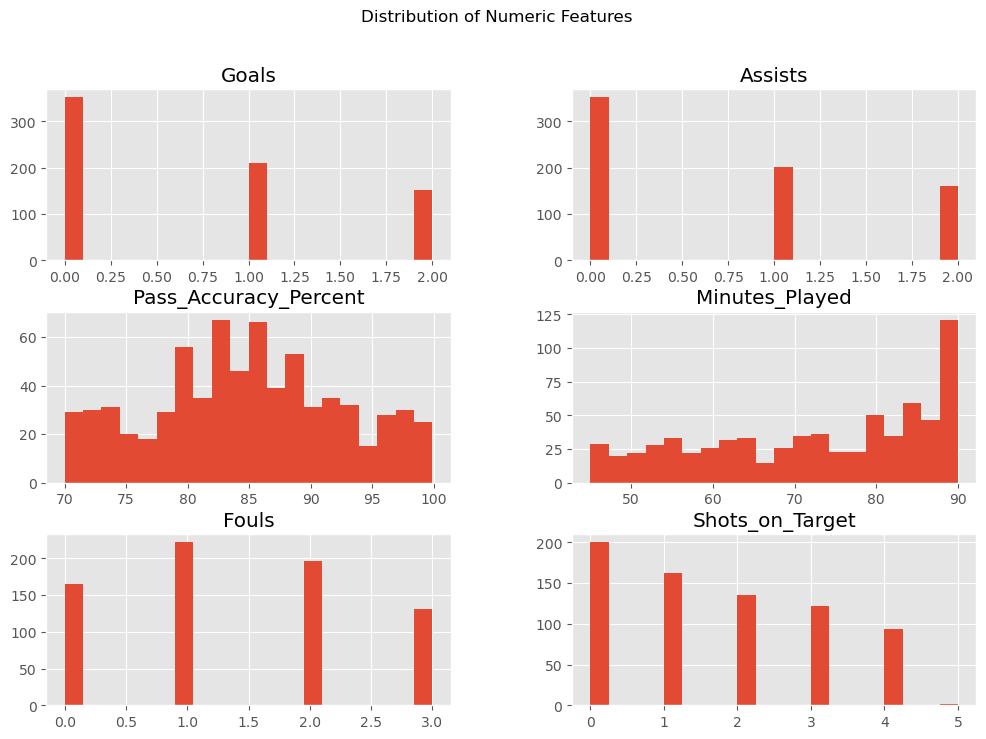

In [13]:
# Distribution of numeric features
numeric_features = data.select_dtypes(include=[np.number]).columns
data[numeric_features].hist(figsize=(12, 8), bins=20)
plt.suptitle("Distribution of Numeric Features")
plt.show()

C:\Users\Hi\AppData\Local\Temp\ipykernel_12600\1807402079.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Fatigue_Level', data=data, palette='coolwarm')


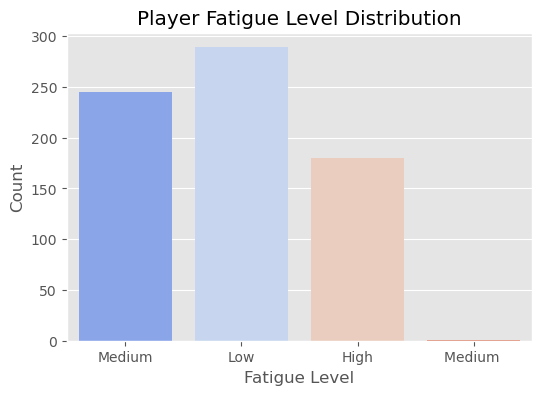

In [14]:
# Fatigue Level distribution
if 'Fatigue_Level' in data.columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x='Fatigue_Level', data=data, palette='coolwarm')
    plt.title("Player Fatigue Level Distribution")
    plt.xlabel("Fatigue Level")
    plt.ylabel("Count")
    plt.show()
else:
    print("Column 'Fatigue_Level' not found in dataset.")

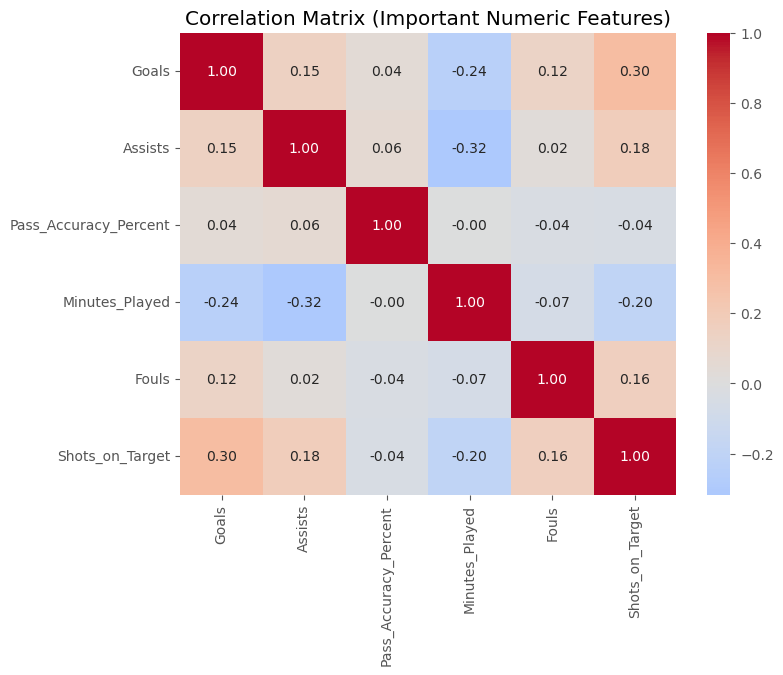

In [15]:
# Correlation Matrix
important_numeric = ['Goals', 'Assists', 'Pass_Accuracy_Percent', 'Minutes_Played', 'Fouls', 'Shots_on_Target']

corr = data[important_numeric].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", center=0)
plt.title("Correlation Matrix (Important Numeric Features)")
plt.show()


C:\Users\Hi\AppData\Local\Temp\ipykernel_12600\2087569591.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Fatigue_Level', y='Minutes_Played', data=data, palette='viridis')


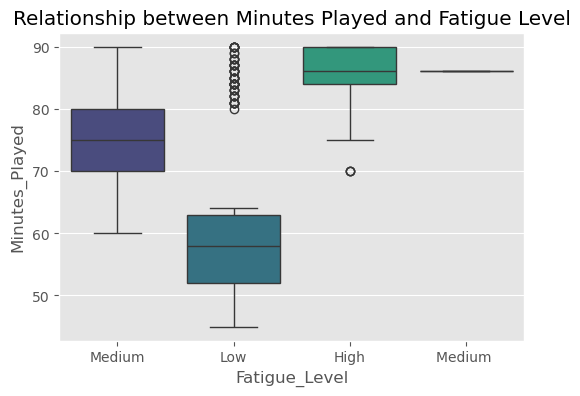

In [16]:
# Relationship between Minutes Played and Fatigue Level
if 'Fatigue_Level' in data.columns and 'Minutes_Played' in data.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Fatigue_Level', y='Minutes_Played', data=data, palette='viridis')
    plt.title("Relationship between Minutes Played and Fatigue Level")
    plt.show()

In [17]:
data['Fatigue_Level'] = data['Fatigue_Level'].str.strip().str.title()

In [18]:
print(data['Fatigue_Level'].value_counts())

Fatigue_Level
Low       289
Medium    246
High      180
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# تأكد أن العمود موجود
if 'Fatigue_Level' in data.columns:
    
    # اختيار الميزات (Features)
    features = ['Goals', 'Assists', 'Pass_Accuracy_Percent', 'Minutes_Played', 'Fouls', 'Shots_on_Target']
    X = data[features]
    y = data['Fatigue_Level']
    
    # تقسيم البيانات
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # إنشاء الموديل وتدريبه
    dt_model = DecisionTreeClassifier(random_state=42)
    dt_model.fit(X_train, y_train)
    
    # التنبؤ
    y_pred = dt_model.predict(X_test)
    
    # تقييم النموذج
    print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred))
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))
else:
    print("Column 'Fatigue_Level' not found.")

Decision Tree Accuracy: 0.8181818181818182

Confusion Matrix:
 [[24  3  7]
 [ 2 49  4]
 [ 7  3 44]]

Classification Report:
               precision    recall  f1-score   support

        High       0.73      0.71      0.72        34
         Low       0.89      0.89      0.89        55
      Medium       0.80      0.81      0.81        54

    accuracy                           0.82       143
   macro avg       0.81      0.80      0.80       143
weighted avg       0.82      0.82      0.82       143



kNN ALGORTHEM

In [20]:
# نستخدم الأعمدة: Goals, Assists, Pass_Accuracy_Percent, Shots_on_Target, Minutes_Played
# نحسب Score لكل لاعب
data['Performance_Score'] = (
    data['Goals']*2 + 
    data['Assists']*1.5 + 
    data['Pass_Accuracy_Percent']/20 + 
    data['Shots_on_Target']*1.2 + 
    data['Minutes_Played']/90
)

# نحدد فئات High_Rating
# 3 فئات: High, Medium, Low
def rate_player(score):
    if score >= 7:
        return 'High'
    elif score >= 4:
        return 'Medium'
    else:
        return 'Low'

data['High_Rating'] = data['Performance_Score'].apply(rate_player)

# data.drop('Performance_Score', axis=1, inplace=True)

# نعرض أول 10 لاعبين مع High_Rating
print(data[['Player', 'Goals', 'Assists', 'Pass_Accuracy_Percent', 'Minutes_Played', 'High_Rating']].head(10))

      Player  Goals  Assists  Pass_Accuracy_Percent  Minutes_Played  \
0   Player_9      2        1                   72.3              69   
1  Player_38      1        1                   85.2              69   
2  Player_46      1        1                   94.9              73   
3  Player_28      1        0                   96.8              48   
4  Player_26      1        2                   96.3              69   
5  Player_43      2        1                   81.8              65   
6  Player_35      2        0                   83.8              48   
7  Player_21      0        0                   97.3              73   
8  Player_46      2        2                   96.1              71   
9  Player_32      1        2                   90.0              73   

  High_Rating  
0        High  
1        High  
2        High  
3        High  
4        High  
5        High  
6        High  
7      Medium  
8        High  
9        High  


In [21]:
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier

# تأكد أن العمود موجود
if 'High_Rating' in data.columns:
    
    # اختيار الميزات (Features)
    features = ['Goals', 'Assists', 'Pass_Accuracy_Percent', 'Minutes_Played', 'Fouls', 'Shots_on_Target']
    X = data[features]
    y = data['High_Rating']
    
    # تحويل التسميات إلى أرقام إذا كانت فئوية
    if y.dtype == 'object':
        le = LabelEncoder()
        y = le.fit_transform(y)
    
    # تقسيم البيانات
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # إنشاء الموديل وتدريبه
    knn_model = KNeighborsClassifier(n_neighbors=5)
    knn_model.fit(X_train, y_train)
    
    # التنبؤ
    y_pred = knn_model.predict(X_test)
    
    # تقييم النموذج
    print("KNN Classifier Accuracy:", accuracy_score(y_test, y_pred))
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
else:
    print("Column 'High_Rating' not found.")

KNN Classifier Accuracy: 0.8601398601398601

Confusion Matrix:
 [[97 10]
 [10 26]]


In [22]:
df = pd.read_excel("C:/Users/Hi/Downloads/SmartCoach_merged.xlsx")
df.head()

,Player,Team,Opponent,Match_Date,Goals,Assists,Pass_Accuracy_%,Minutes_Played,Fouls,Shots_on_Target,Fatigue_Level
0,Player_9,Al-Ahli,Al-Ahli,2025-09-30,2,1,72.3,69,2,3,Medium
1,Player_38,Al-Ittihad,Al-Shabab,2025-05-04,1,1,85.2,69,0,4,Medium
2,Player_46,Al-Shabab,Al-Ittihad,2025-02-20,1,1,94.9,73,0,1,Medium
3,Player_28,Al-Ittihad,Al-Shabab,2025-09-13,1,0,96.8,48,1,2,Low
4,Player_26,Al-Nassr,Al-Nassr,2025-03-18,1,2,96.3,69,2,0,Medium


In [23]:
df = df.copy()

# تحويل الأعمدة الرقمية
numeric_cols = ['Goals','Assists','Pass_Accuracy_%','Minutes_Played','Fouls','Shots_on_Target','Fatigue_Level']
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# إزالة % لو موجود
df['Pass_Accuracy_%'] = df['Pass_Accuracy_%'].astype(str).str.replace('%','')
df['Pass_Accuracy_%'] = pd.to_numeric(df['Pass_Accuracy_%'], errors='coerce')

Team and Opponent

In [24]:
le_team = LabelEncoder()
le_opp  = LabelEncoder()

df['Team_le'] = le_team.fit_transform(df['Team'].astype(str))
df['Opponent_le'] = le_opp.fit_transform(df['Opponent'].astype(str))

In [25]:
df['Ready'] = np.where(df['Fatigue_Level'] <= 40, 1, 0) #Create a Ready variable

In [31]:
# عينة موحدة من الميزات الأساسية
COMMON_FEATURES = [
    'Minutes_Played',
    'Shots_on_Target',
    'Pass_Accuracy_%',
    'Assists',
    'Fatigue_Level',
    'Team_le',
    'Opponent_le'
]

X_common = df[COMMON_FEATURES].copy()

# أهداف الموديلات
y_reg = df['Goals']
y_clf = df['Ready']

In [32]:
X_train_common, X_test_common = train_test_split(
    X_common, 
    test_size=0.2, 
    random_state=42
)

# مطابقة نفس الفهارس (indices)
train_idx = X_train_common.index
test_idx  = X_test_common.index

# الـ Targets يكون نفس الفكرة
y_train_reg = y_reg.loc[train_idx]
y_test_reg  = y_reg.loc[test_idx]

y_train_clf = y_clf.loc[train_idx]
y_test_clf  = y_clf.loc[test_idx]

In [33]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
le_opponent = LabelEncoder()
le_team = LabelEncoder()

df_model = df.copy()

# ترميز Opponent و Team إذا موجودين
if 'Opponent' in df_model.columns:
    df_model['Opponent_le'] = le_opponent.fit_transform(df_model['Opponent'].astype(str))
if 'Team' in df_model.columns:
    df_model['Team_le'] = le_team.fit_transform(df_model['Team'].astype(str))

# --- إنشاء target للتصنيف Ready/Not Ready باستخدام Fatigue_Level ---
# إذا Fatigue_Level ≤ 40 --> Ready (1), >40 --> Not Ready (0)
df_model['Ready'] = np.where(df_model['Fatigue_Level'] <= 40, 1, 0)

# اختيار الأعمدة الميزات المشتركة للـ Regression
features_reg = []
for c in ['Minutes_Played','Shots_on_Target','Pass_Accuracy_%','Fatigue_Level','Assists','Opponent_le','Team_le']:
    if c in df_model.columns:
        features_reg.append(c)

print("Features for regression:", features_reg)

# ميزات للتصنيف Decision Tree
features_clf = []
for c in ['Fatigue_Level','Minutes_Played','Pass_Accuracy_%','Shots_on_Target','Fouls','Assists','Opponent_le']:
    if c in df_model.columns:
        features_clf.append(c)

print("Features for classification:", features_clf)

# تكوين مجموعة للـ clustering (نستخدم الأداء فقط)
features_cluster = []
for c in ['Goals','Assists','Pass_Accuracy_%','Shots_on_Target']:
    if c in df_model.columns:
        features_cluster.append(c)

print("Features for clustering:", features_cluster)

Features for regression: ['Minutes_Played', 'Shots_on_Target', 'Pass_Accuracy_%', 'Fatigue_Level', 'Assists', 'Opponent_le', 'Team_le']
Features for classification: ['Fatigue_Level', 'Minutes_Played', 'Pass_Accuracy_%', 'Shots_on_Target', 'Fouls', 'Assists', 'Opponent_le']
Features for clustering: ['Goals', 'Assists', 'Pass_Accuracy_%', 'Shots_on_Target']


In [34]:
REG_FEATURES = [
    'Minutes_Played',
    'Shots_on_Target',
    'Pass_Accuracy_%',
    'Fatigue_Level',
    'Assists'
]

X_train_reg = df.loc[train_idx, REG_FEATURES]
X_test_reg  = df.loc[test_idx, REG_FEATURES]

# Scaling
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled  = scaler_reg.transform(X_test_reg)

# Model
reg = RandomForestRegressor(n_estimators=200, random_state=42)
reg.fit(X_train_reg_scaled, y_train_reg)

# Predictions
pred_reg = reg.predict(X_test_reg_scaled)

print("===== Regression Results =====")
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, pred_reg)))
print("MAE :", mean_absolute_error(y_test_reg, pred_reg))
print("R²  :", r2_score(y_test_reg, pred_reg))

c:\Users\Hi\anaconda3\Lib\site-packages\sklearn\utils\extmath.py:1137: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
c:\Users\Hi\anaconda3\Lib\site-packages\sklearn\utils\extmath.py:1142: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
c:\Users\Hi\anaconda3\Lib\site-packages\sklearn\utils\extmath.py:1162: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


===== Regression Results =====
RMSE: 0.7809810935813163
MAE : 0.6072027972027972
R²  : 0.13970971168437019


In [35]:
reg_results = pd.DataFrame({
    "Player": df.loc[test_idx, "Player"],
    "Actual_Goals": y_test_reg,
    "Predicted_Goals": pred_reg
})
reg_results.head(20)

,Player,Actual_Goals,Predicted_Goals
120,Player_16,2,0.415
570,Rami Al-Salem,0,0.000
39,Player_45,2,0.690
294,Player_2,0,0.900
666,Francisco Calvo,0,0.000
437,Player_43,2,0.805
65,Player_43,1,0.950
499,Player_39,2,1.205
78,Player_38,0,0.895
653,Flores da Silva,1,0.990


In [ ]:
CLUSTER_FEATURES = [
    'Goals',
    'Assists',
    'Pass_Accuracy_%',
    'Shots_on_Target'
]

X_cluster = df[CLUSTER_FEATURES].copy().dropna()

# Scaling
scaler_clust = StandardScaler()
X_cluster_scaled = scaler_clust.fit_transform(X_cluster)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_cluster_scaled)

df['Cluster'] = clusters

sil = silhouette_score(X_cluster_scaled, clusters)
print("\n===== K-Means Clustering =====")
print("Silhouette Score:", sil)
df[['Player','Goals','Assists','Cluster']].head(10)

print("cluster 0: لاعبين بأداء هجومي أعلى" \
" cluster 1: لاعبين متوسطي الأداء" \
" cluster 2: لاعبين منخفضي الأداء ")

c:\Users\Hi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(



===== K-Means Clustering =====
Silhouette Score: 0.2724038124833629
cluster 0: لاعبين بأداء هجومي أعلى cluster 1: لاعبين متوسطي الأداء cluster 2: لاعبين منخفضي الأداء 


In [42]:
cluster_results = pd.DataFrame({
    "Player": df["Player"],
    "Cluster": df["Cluster"]
})
cluster_results.head(20)

,Player,Cluster
0,Player_9,1
1,Player_38,1
2,Player_46,0
3,Player_28,0
4,Player_26,0
5,Player_43,1
6,Player_35,1
7,Player_21,2
8,Player_46,0
9,Player_32,0
